In [10]:
!pip install GEOparse

In [1]:
import pandas as pd
train = pd.read_csv("data_set_ALL_AML_train.csv")
test = pd.read_csv("data_set_ALL_AML_independent.csv")
labels = pd.read_csv("actual.csv")
print(train.shape, test.shape, labels.shape)
print(train.iloc[:3, :8])
print(labels.head())

(7129, 78) (7129, 70) (72, 2)
                      Gene Description Gene Accession Number    1 call    2  \
0  AFFX-BioB-5_at (endogenous control)        AFFX-BioB-5_at -214    A -139   
1  AFFX-BioB-M_at (endogenous control)        AFFX-BioB-M_at -153    A  -73   
2  AFFX-BioB-3_at (endogenous control)        AFFX-BioB-3_at  -58    A   -1   

  call.1    3 call.2  
0      A  -76      A  
1      A  -49      A  
2      A -307      A  
   patient cancer
0        1    ALL
1        2    ALL
2        3    ALL
3        4    ALL
4        5    ALL


In [2]:
import numpy as np

def get_patient_cols(df):
    return [c for c in df.columns if str(c).isdigit()]

train_ids = get_patient_cols(train)
test_ids = get_patient_cols(test)
print("Train hasta sayısı:", len(train_ids), "| Test hasta sayısı:", len(test_ids))
print("Train sütun sırası:", train_ids)
print("Test sütun sırası:", test_ids)

# Gen × örnek -> örnek × gen (index: hasta no, sütun: gen accession)
def to_samples(df, ids):
    X = df[["Gene Accession Number"] + ids].set_index("Gene Accession Number").T
    X.index = X.index.astype(int)
    X.index.name = "patient"
    return X.apply(pd.to_numeric)

X_train = to_samples(train, train_ids)
X_test = to_samples(test, test_ids)

# Etiketler: hasta numarasıyla eşleştir
labels["patient"] = labels["patient"].astype(int)
lab = labels.set_index("patient")["cancer"]
y_train = lab.loc[X_train.index]
y_test = lab.loc[X_test.index]

# Doğrulamalar
print("\nÇakışan hasta var mı?", set(X_train.index) & set(X_test.index))
print("Birleşim 1..72 mi?", sorted(set(X_train.index) | set(X_test.index)) == list(range(1, 73)))
print("\nTrain sınıflar:\n", y_train.value_counts())
print("Test sınıflar:\n", y_test.value_counts())
print("Toplam:\n", lab.value_counts())
print("\nGen accession tekrarı (train):", X_train.columns.duplicated().sum())
print("Gen sırası train/test aynı mı?", list(X_train.columns) == list(X_test.columns))

Train hasta sayısı: 38 | Test hasta sayısı: 34
Train sütun sırası: ['1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '20', '21', '22', '23', '24', '25', '26', '27', '34', '35', '36', '37', '38', '28', '29', '30', '31', '32', '33']
Test sütun sırası: ['39', '40', '42', '47', '48', '49', '41', '43', '44', '45', '46', '70', '71', '72', '68', '69', '67', '55', '56', '59', '52', '53', '51', '50', '54', '57', '58', '60', '61', '65', '66', '63', '64', '62']

Çakışan hasta var mı? set()
Birleşim 1..72 mi? True

Train sınıflar:
 cancer
ALL    27
AML    11
Name: count, dtype: int64
Test sınıflar:
 cancer
ALL    20
AML    14
Name: count, dtype: int64
Toplam:
 cancer
ALL    47
AML    25
Name: count, dtype: int64

Gen accession tekrarı (train): 0
Gen sırası train/test aynı mı? True


In [3]:
all_X = pd.concat([X_train, X_test]).sort_index()

print("Eksik değer (NaN):", all_X.isna().sum().sum())
print("INF değer:", np.isinf(all_X.values).sum())
print("Negatif değer sayısı:", (all_X.values < 0).sum(),
      f"({(all_X.values < 0).mean()*100:.1f}%)")
print("Min / Max:", all_X.values.min(), all_X.values.max())
print("20'nin altındaki değer oranı: %.1f%%" % ((all_X.values < 20).mean()*100))
print("16000'in üstündeki değer sayısı:", (all_X.values > 16000).sum())

# Train ve test ayrı ayrı özet
for name, X in [("train", X_train), ("test", X_test)]:
    print(f"\n{name}: ortalama={X.values.mean():.1f}, medyan={np.median(X.values):.1f}, "
          f"std={X.values.std():.1f}")

# Gen düzeyinde varyans özeti
var = all_X.var()
print("\nVaryansı sıfır olan gen sayısı:", (var == 0).sum())
print(var.describe())

Eksik değer (NaN): 0
INF değer: 0
Negatif değer sayısı: 147174 (28.7%)
Min / Max: -28400 71369
20'nin altındaki değer oranı: 32.7%
16000'in üstündeki değer sayısı: 4259

train: ortalama=637.7, medyan=127.0, std=2426.2

test: ortalama=599.8, medyan=114.0, std=2459.5

Varyansı sıfır olan gen sayısı: 0
count    7.129000e+03
mean     8.002843e+05
std      5.360559e+06
min      7.130561e+02
25%      9.308350e+03
50%      3.433554e+04
75%      1.310090e+05
max      2.526051e+08
dtype: float64


Call oranları:
 A    0.702
P    0.282
M    0.016
Name: proportion, dtype: float64
      count         mean          std      min    25%    50%     75%      max
c                                                                            
A  360139.0    50.040876   484.766877 -28400.0  -74.0   33.0   171.0  15351.0
M    8273.0   362.704460   415.037863  -2422.0  123.0  251.0   474.0   8808.0
P  144876.0  2050.737527  4204.365509  -1529.0  309.0  662.0  1523.0  71369.0
Call'a göre negatif oranı:
 c
A    0.406
M    0.039
P    0.005
Name: v, dtype: float64


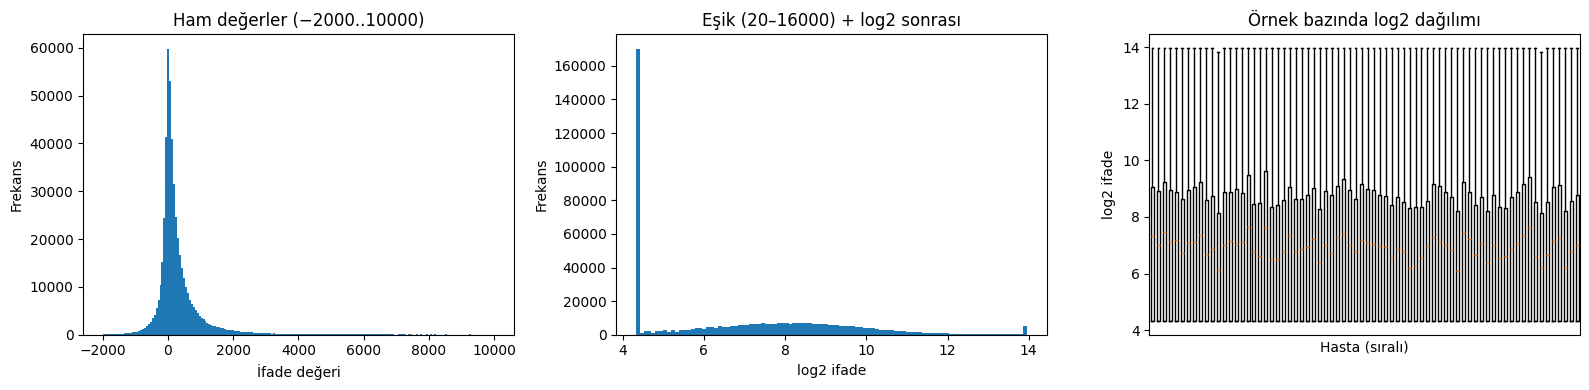

In [4]:
import matplotlib.pyplot as plt

def get_calls(df):
    cols = list(df.columns)
    out = {}
    for i, c in enumerate(cols):
        if str(c).isdigit():
            assert str(cols[i+1]).startswith("call")
            out[int(c)] = df.iloc[:, i+1].values
    C = pd.DataFrame(out, index=df["Gene Accession Number"]).T
    C.index.name = "patient"
    return C

all_C = pd.concat([get_calls(train), get_calls(test)]).sort_index()
all_C = all_C[all_X.columns]

vals = all_X.values.ravel()
calls = all_C.values.ravel()
print("Call oranları:\n", pd.Series(calls).value_counts(normalize=True).round(3))

df_vc = pd.DataFrame({"v": vals, "c": calls})
print(df_vc.groupby("c")["v"].describe())
print("Call'a göre negatif oranı:\n", df_vc.groupby("c")["v"].apply(lambda s: (s < 0).mean()).round(3))

# Alt-üst eşik + log2
X_log = np.log2(all_X.clip(20, 16000))

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].hist(vals, bins=200, range=(-2000, 10000))
ax[0].set(title="Ham değerler (−2000..10000)", xlabel="İfade değeri", ylabel="Frekans")
ax[1].hist(X_log.values.ravel(), bins=100)
ax[1].set(title="Eşik (20–16000) + log2 sonrası", xlabel="log2 ifade", ylabel="Frekans")
ax[2].boxplot([X_log.loc[i].values for i in X_log.index], showfliers=False)
ax[2].set(title="Örnek bazında log2 dağılımı", xlabel="Hasta (sıralı)", ylabel="log2 ifade")
ax[2].set_xticks([])
plt.tight_layout()
plt.savefig("fig_distributions.png", dpi=300)
plt.show()

Filtre sonrası gen sayısı: 3571 / 7129
Açıklanan varyans (ilk 10 PC): [0.161 0.114 0.06  0.047 0.038 0.032 0.026 0.025 0.021 0.02 ]
İlk 2 PC toplam: 0.275 | İlk 10 PC toplam: 0.544


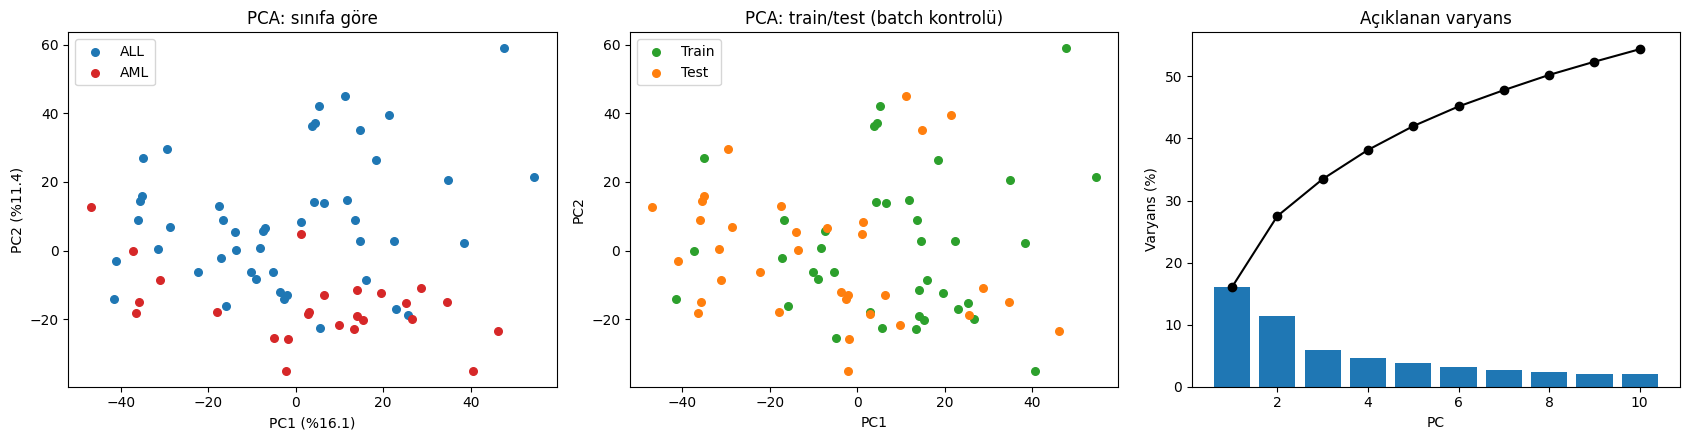

In [5]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

X_c = all_X.clip(100, 16000)
keep = ((X_c.max() / X_c.min()) > 5) & ((X_c.max() - X_c.min()) > 500)
print("Filtre sonrası gen sayısı:", keep.sum(), "/", len(keep))

X_f = np.log2(X_c.loc[:, keep])
Z = StandardScaler().fit_transform(X_f)

y_all = lab.loc[X_f.index]
is_train = X_f.index.isin(X_train.index)

pca = PCA(n_components=10, random_state=SEED if "SEED" in globals() else 42)
P = pca.fit_transform(Z)
ev = pca.explained_variance_ratio_
print("Açıklanan varyans (ilk 10 PC):", ev.round(3))
print("İlk 2 PC toplam:", ev[:2].sum().round(3), "| İlk 10 PC toplam:", ev.sum().round(3))

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
for cls, col in [("ALL", "tab:blue"), ("AML", "tab:red")]:
    m = (y_all == cls).values
    ax[0].scatter(P[m, 0], P[m, 1], c=col, label=cls, s=30)
ax[0].set(title="PCA: sınıfa göre", xlabel=f"PC1 (%{ev[0]*100:.1f})", ylabel=f"PC2 (%{ev[1]*100:.1f})")
ax[0].legend()

for name, m, col in [("Train", is_train, "tab:green"), ("Test", ~is_train, "tab:orange")]:
    ax[1].scatter(P[m, 0], P[m, 1], c=col, label=name, s=30)
ax[1].set(title="PCA: train/test (batch kontrolü)", xlabel="PC1", ylabel="PC2")
ax[1].legend()

ax[2].bar(range(1, 11), ev * 100)
ax[2].plot(range(1, 11), np.cumsum(ev) * 100, "k-o")
ax[2].set(title="Açıklanan varyans", xlabel="PC", ylabel="Varyans (%)")
plt.tight_layout()
plt.savefig("fig_pca.png", dpi=300)
plt.show()

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


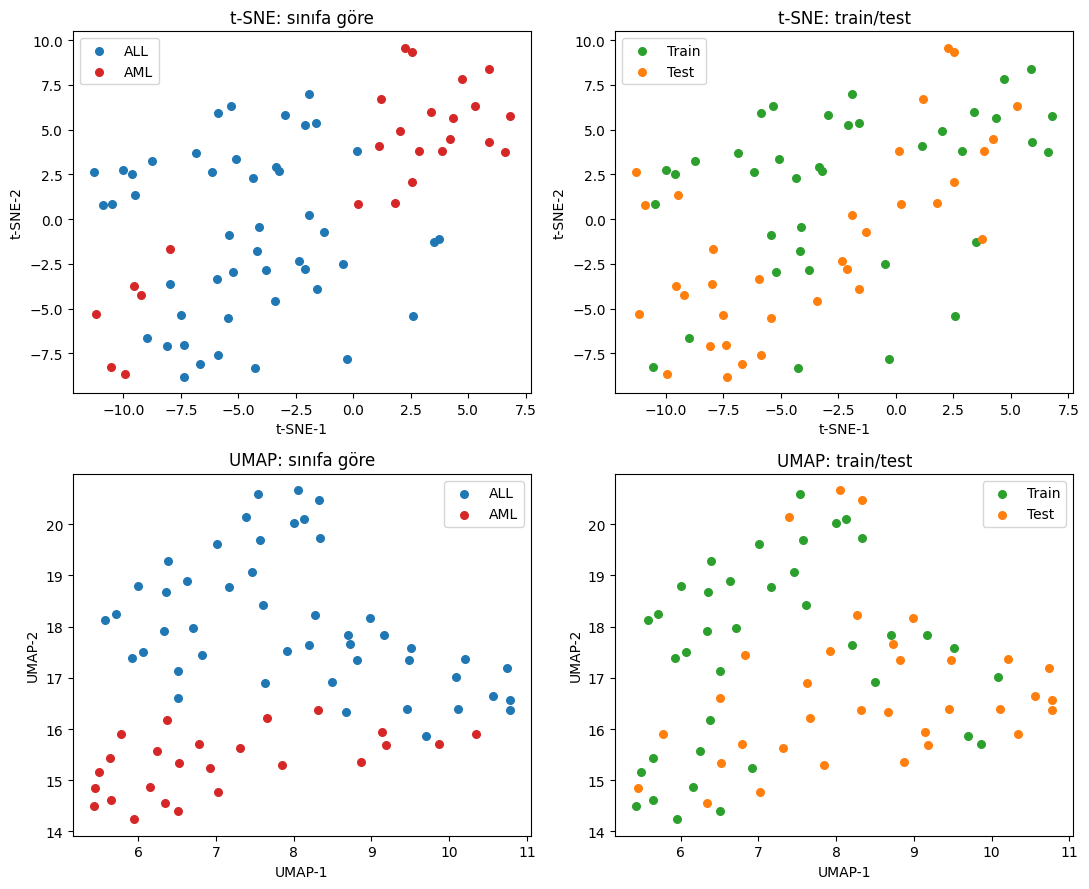

In [6]:
from sklearn.manifold import TSNE
import umap

# PCA'nın ilk 10 bileşeni üzerinden (Z'den) 2B gömme
tsne = TSNE(n_components=2, perplexity=15, random_state=42, init="pca")
T = tsne.fit_transform(Z)

um = umap.UMAP(n_components=2, n_neighbors=10, min_dist=0.3, random_state=42)
U = um.fit_transform(Z)

fig, ax = plt.subplots(2, 2, figsize=(11, 9))
for row, (name, E) in enumerate([("t-SNE", T), ("UMAP", U)]):
    for cls, col in [("ALL", "tab:blue"), ("AML", "tab:red")]:
        m = (y_all == cls).values
        ax[row, 0].scatter(E[m, 0], E[m, 1], c=col, label=cls, s=30)
    ax[row, 0].set(title=f"{name}: sınıfa göre", xlabel=f"{name}-1", ylabel=f"{name}-2")
    ax[row, 0].legend()
    for sname, m, col in [("Train", is_train, "tab:green"), ("Test", ~is_train, "tab:orange")]:
        ax[row, 1].scatter(E[m, 0], E[m, 1], c=col, label=sname, s=30)
    ax[row, 1].set(title=f"{name}: train/test", xlabel=f"{name}-1", ylabel=f"{name}-2")
    ax[row, 1].legend()
plt.tight_layout()
plt.savefig("fig_tsne_umap.png", dpi=300)
plt.show()

q < 0.05 olan gen sayısı: 986
q < 0.01 olan gen sayısı: 548
             gene             p             q  log2FC_ALL_minus_AML
1651    U46499_at  2.584522e-12  5.220681e-09             -3.190413
1181    M84526_at  2.923932e-12  5.220681e-09             -4.725821
955     M23197_at  1.090183e-11  1.073725e-08             -2.171193
978     M27891_at  1.202716e-11  1.073725e-08             -4.807517
2480    X95735_at  2.527389e-11  1.805061e-08             -3.289352
3440    M31523_at  3.504030e-11  2.085482e-08              2.073777
3037  L09209_s_at  6.570708e-11  3.352000e-08             -2.568568
435     D88422_at  1.855896e-10  8.284257e-08             -3.319930
625     J05243_at  3.775398e-10  1.497994e-07              1.994976
873     M11722_at  4.724681e-10  1.570768e-07              3.783291


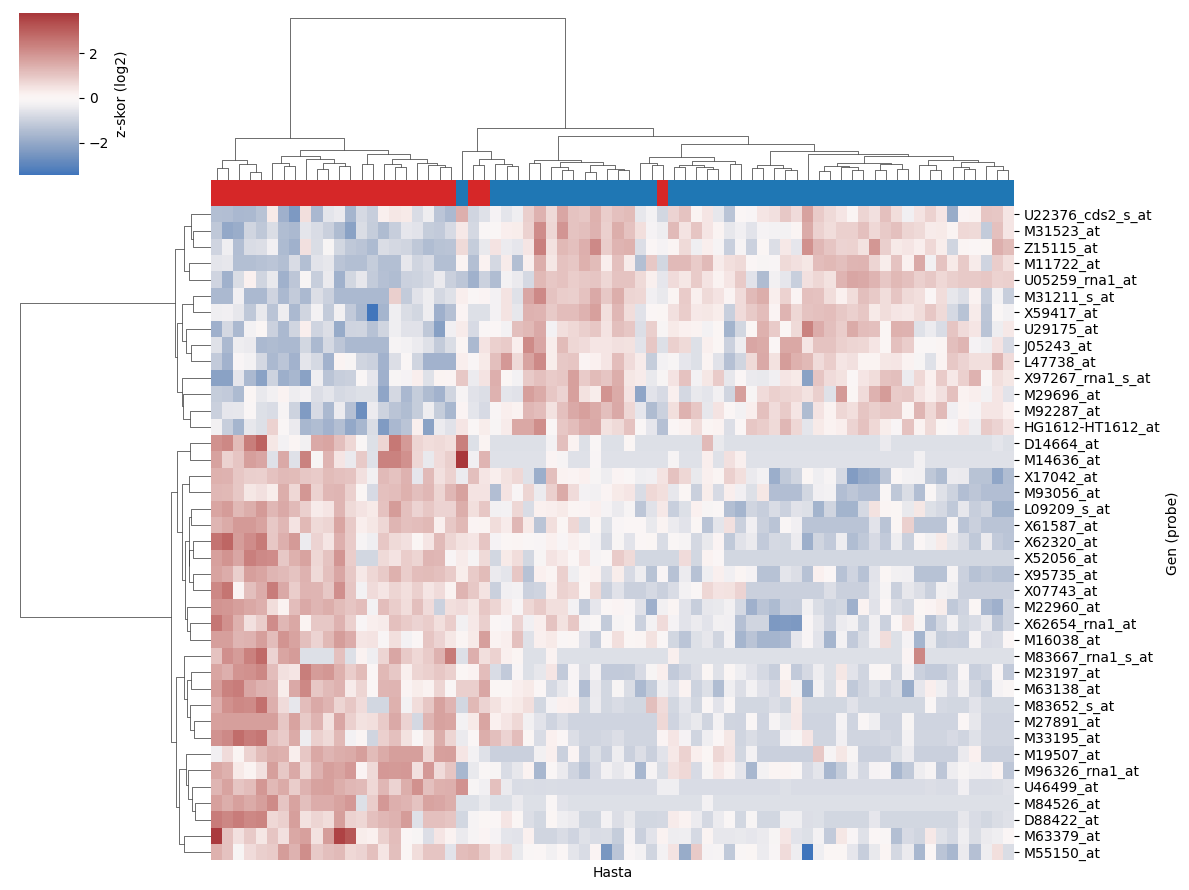

In [7]:
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests
import seaborn as sns

# Gen bazında ALL vs AML: Mann-Whitney U + BH düzeltmesi
is_all = (y_all == "ALL").values
pvals = []
for g in X_f.columns:
    a = X_f.loc[is_all, g].values
    b = X_f.loc[~is_all, g].values
    pvals.append(mannwhitneyu(a, b, alternative="two-sided").pvalue)
pvals = np.array(pvals)
qvals = multipletests(pvals, method="fdr_bh")[1]

res = pd.DataFrame({
    "gene": X_f.columns,
    "p": pvals,
    "q": qvals,
    "log2FC_ALL_minus_AML": X_f.loc[is_all].mean().values - X_f.loc[~is_all].mean().values
}).sort_values("p")
print("q < 0.05 olan gen sayısı:", (res.q < 0.05).sum())
print("q < 0.01 olan gen sayısı:", (res.q < 0.01).sum())
print(res.head(10))

# En iyi 40 gen: ısı haritası + hiyerarşik kümeleme
top = res.head(40)["gene"].tolist()
H = X_f[top]
H_z = (H - H.mean()) / H.std()

row_colors = pd.Series(y_all.values, index=H.index).map({"ALL": "tab:blue", "AML": "tab:red"})
g = sns.clustermap(H_z.T, col_colors=row_colors.values, cmap="vlag", center=0,
                   method="ward", metric="euclidean", figsize=(12, 9),
                   xticklabels=False, yticklabels=True, cbar_kws={"label": "z-skor (log2)"})
g.ax_heatmap.set_xlabel("Hasta")
g.ax_heatmap.set_ylabel("Gen (probe)")
g.savefig("fig_heatmap_top40.png", dpi=300)
plt.show()

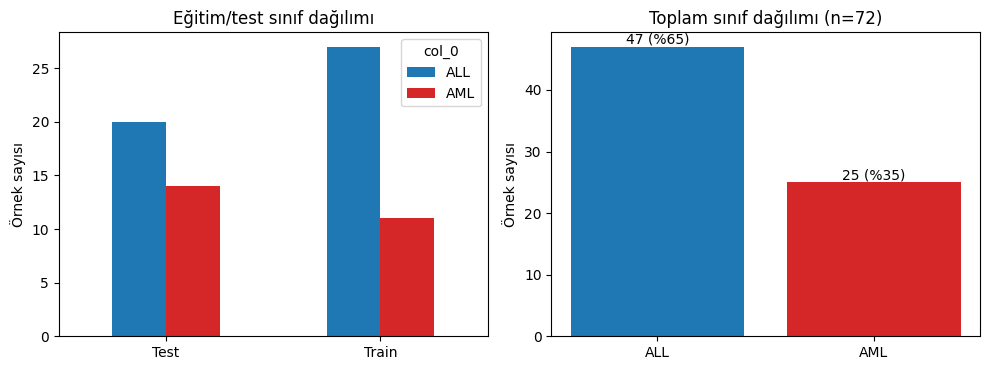

     PC  p_ALL  p_AML  q_ALL  q_AML
0   PC1  0.011  0.132  0.076  0.378
1   PC2  0.906  0.494  0.953  0.622
2   PC3  0.498  0.338  0.622  0.563
3   PC4  0.040  0.011  0.199  0.076
4   PC5  0.007  0.338  0.076  0.563
5   PC6  0.054  0.338  0.217  0.563
6   PC7  0.583  0.681  0.686  0.757
7   PC8  0.471  0.075  0.622  0.251
8   PC9  0.287  0.460  0.563  0.622
9  PC10  0.250  1.000  0.563  1.000
ALL içinde train/test farkı q<0.05 olan gen: 6 / 3571


In [8]:
# 1) Sınıf dağılımı grafiği
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
ct = pd.crosstab(np.where(is_train, "Train", "Test"), y_all.values)
ct.plot(kind="bar", ax=ax[0], color=["tab:blue", "tab:red"], rot=0)
ax[0].set(title="Eğitim/test sınıf dağılımı", xlabel="", ylabel="Örnek sayısı")
tot = pd.Series(y_all.values).value_counts()
ax[1].bar(tot.index, tot.values, color=["tab:blue", "tab:red"])
ax[1].set(title="Toplam sınıf dağılımı (n=72)", ylabel="Örnek sayısı")
for i, v in enumerate(tot.values):
    ax[1].text(i, v + 0.5, f"{v} (%{v/72*100:.0f})", ha="center")
plt.tight_layout()
plt.savefig("fig_class_dist.png", dpi=300)
plt.show()

# 2) Train vs test: ilk 10 PC skorları, sınıf içinde
rows = []
for k in range(10):
    p_all = mannwhitneyu(P[is_train & is_all, k], P[~is_train & is_all, k]).pvalue
    p_aml = mannwhitneyu(P[is_train & ~is_all, k], P[~is_train & ~is_all, k]).pvalue
    rows.append((f"PC{k+1}", p_all, p_aml))
bt = pd.DataFrame(rows, columns=["PC", "p_ALL", "p_AML"])
allp = np.concatenate([bt.p_ALL, bt.p_AML])
adj = multipletests(allp, method="fdr_bh")[1]
bt["q_ALL"], bt["q_AML"] = adj[:10], adj[10:]
print(bt.round(3))

# 3) Gen düzeyinde train vs test (yalnızca ALL, 27 vs 20)
pv = np.array([mannwhitneyu(X_f.loc[is_train & is_all, g], X_f.loc[~is_train & is_all, g]).pvalue
               for g in X_f.columns])
qv = multipletests(pv, method="fdr_bh")[1]
print("ALL içinde train/test farkı q<0.05 olan gen:", (qv < 0.05).sum(), "/", len(qv))

In [13]:
import GEOparse
gse = GEOparse.get_GEO("GSE14062", destdir="./geo_cache", silent=True)
print("Platformlar:", list(gse.gpls.keys()))
print("Örnek sayısı:", len(gse.gsms))

meta = gse.phenotype_data
print(meta.shape)
print(meta.columns.tolist())

/usr/local/lib/python3.13/dist-packages/GEOparse/GEOparse.py:401: DtypeWarning: Columns (2) have mixed types. Specify dtype option on import or set low_memory=False.
  return read_csv(StringIO(data), index_col=None, sep="\t")


Platformlar: ['GPL570']
Örnek sayısı: 140
(140, 36)
['title', 'geo_accession', 'status', 'submission_date', 'last_update_date', 'type', 'channel_count', 'source_name_ch1', 'organism_ch1', 'taxid_ch1', 'characteristics_ch1.0.Leukemia samples', 'characteristics_ch1.1.Bone Marrow', 'treatment_protocol_ch1', 'growth_protocol_ch1', 'molecule_ch1', 'extract_protocol_ch1', 'label_ch1', 'label_protocol_ch1', 'hyb_protocol', 'scan_protocol', 'description', 'data_processing', 'platform_id', 'contact_name', 'contact_email', 'contact_laboratory', 'contact_department', 'contact_institute', 'contact_address', 'contact_city', 'contact_zip/postal_code', 'contact_country', 'supplementary_file', 'series_id', 'data_row_count', 'relation']


In [14]:
meta = gse.phenotype_data

# 1) Etiketler title'dan
grp = meta["title"].str.replace(r"\s*-\s*sample\s*\d+", "", regex=True).str.strip()
print(grp.value_counts())

# 2) Normalizasyon ve açıklama metni (tam)
print("\nDATA PROCESSING:\n", meta["data_processing"].iloc[0])
print("\nDESCRIPTION:\n", meta["description"].iloc[0])

# 3) İfade matrisi (prob x örnek)
expr = gse.pivot_samples("VALUE")
print("\nİfade matrisi:", expr.shape)
print("Min / Max:", np.nanmin(expr.values), np.nanmax(expr.values))
print("NaN sayısı:", int(expr.isna().sum().sum()))
print("Medyan:", np.nanmedian(expr.values))

# 4) Platform ek açıklama sütunları
gpl = gse.gpls["GPL570"].table
print("\nGPL570 sütunları:", gpl.columns.tolist())
print(gpl[["ID", "Gene Symbol"]].head())
print("Sembolü boş prob oranı:", gpl["Gene Symbol"].isna().mean().round(3))

title
ALL without MLL    90
AML without MLL    26
ALL with MLL       16
AML with MLL        8
Name: count, dtype: int64

DATA PROCESSING:
 The data were normalized using R software [www.r-ptoject.org] with BioConductor package [www.bioconductor.org]

DESCRIPTION:
 Gene expression data from pediatric acute leukemia samples at diagnosis

İfade matrisi: (54675, 140)
Min / Max: 2.14426944 14.51894644
NaN sayısı: 0
Medyan: 4.2914310975

GPL570 sütunları: ['ID', 'GB_ACC', 'SPOT_ID', 'Species Scientific Name', 'Annotation Date', 'Sequence Type', 'Sequence Source', 'Target Description', 'Representative Public ID', 'Gene Title', 'Gene Symbol', 'ENTREZ_GENE_ID', 'RefSeq Transcript ID', 'Gene Ontology Biological Process', 'Gene Ontology Cellular Component', 'Gene Ontology Molecular Function']
          ID       Gene Symbol
0  1007_s_at  DDR1 /// MIR4640
1    1053_at              RFC2
2     117_at             HSPA6
3     121_at              PAX8
4  1255_g_at            GUCA1A
Sembolü boş prob oran

Sınıflar:
 title
ALL    106
AML     34
Name: count, dtype: int64 
MLL+: 24
Tek genli prob: 42986 | benzersiz gen: 21655
Açıklanan varyans: [0.204 0.117 0.067 0.047 0.039 0.029 0.026 0.023 0.02  0.019] | ilk 2 PC: 0.321


/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


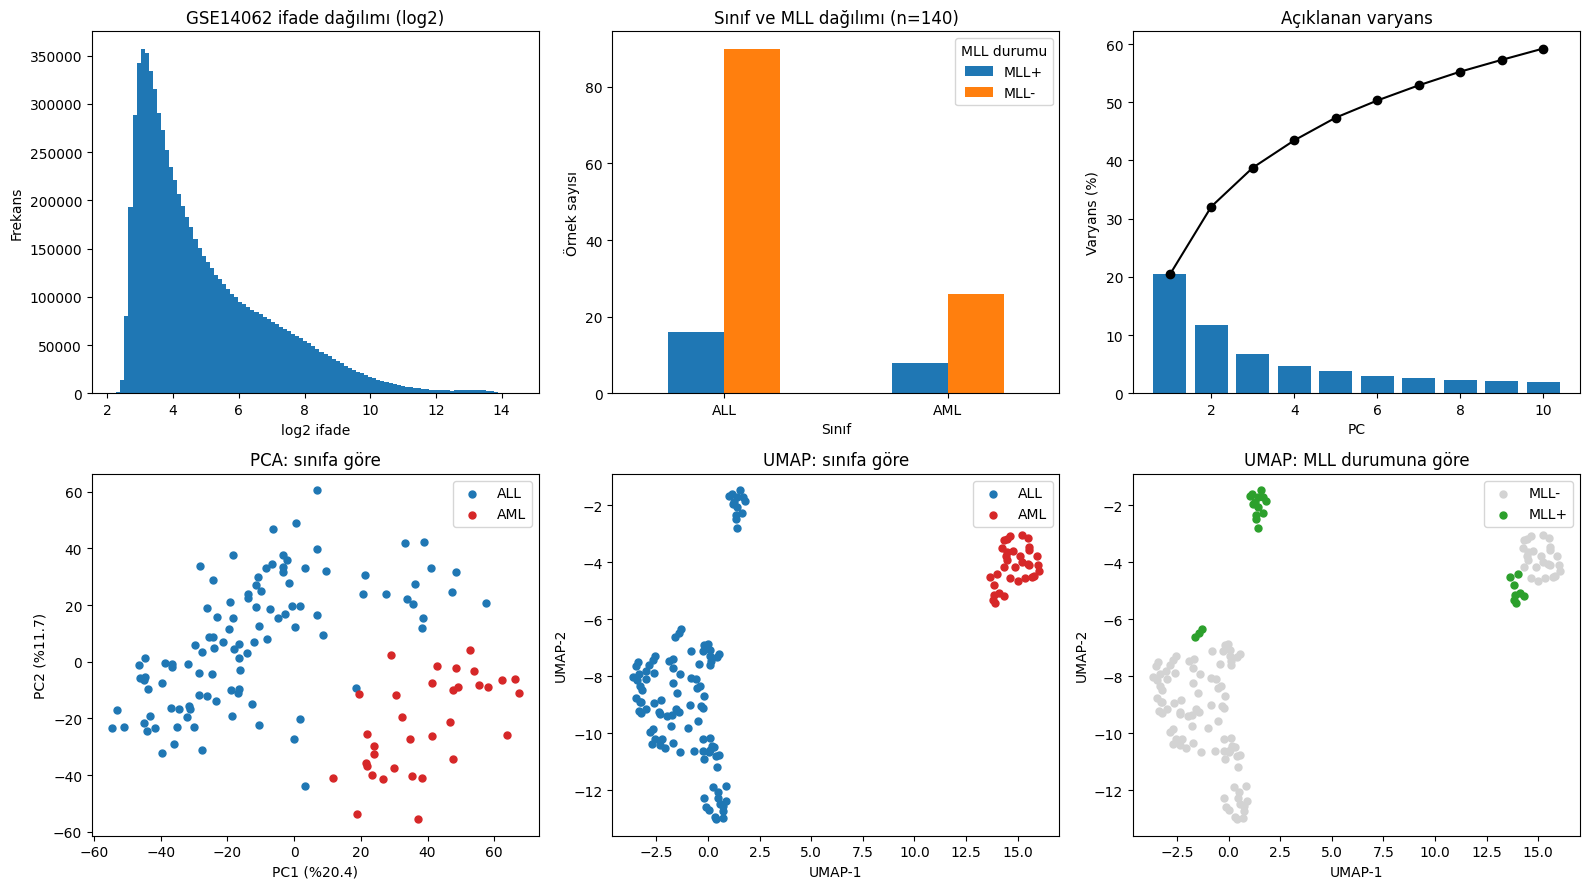

In [16]:
# [GSE14062-EDA] Dağılım, sınıf/MLL dağılımı, PCA ve UMAP
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import umap
SEED = 42

meta = gse.phenotype_data
grp = meta["title"].str.replace(r"\s*-\s*sample\s*\d+", "", regex=True).str.strip()
y2 = grp.str.split().str[0]
mll = grp.str.contains(r"\bwith MLL")

X2 = expr.T.astype(float)           # örnek x prob
y2 = y2.loc[X2.index]; mll = mll.loc[X2.index]
print("Sınıflar:\n", y2.value_counts(), "\nMLL+:", int(mll.sum()))

# Prob -> gen sembolü (etiketsiz kural: çok genli probları at, aynı gende ortalaması en yüksek probu seç)
gpl = gse.gpls["GPL570"].table
ann = gpl[["ID", "Gene Symbol"]].dropna()
ann = ann[~ann["Gene Symbol"].str.contains("///")]
ann = ann[ann["ID"].isin(X2.columns)].copy()
ann["mean"] = ann["ID"].map(X2.mean())
best = ann.sort_values("mean", ascending=False).drop_duplicates("Gene Symbol")
X_gene = X2[best["ID"]].copy()
X_gene.columns = best["Gene Symbol"].values
print("Tek genli prob:", len(ann), "| benzersiz gen:", X_gene.shape[1])

# Etiketsiz varyans filtresi: en yüksek varyanslı 5000 gen (yalnızca EDA için)
top_var = X_gene.var().sort_values(ascending=False).head(5000).index
Xf = X_gene[top_var]
Z2 = StandardScaler().fit_transform(Xf)

pca2 = PCA(n_components=10, random_state=SEED)
P2 = pca2.fit_transform(Z2); ev2 = pca2.explained_variance_ratio_
print("Açıklanan varyans:", ev2.round(3), "| ilk 2 PC:", ev2[:2].sum().round(3))

U2 = umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.3, random_state=SEED).fit_transform(Z2)

fig, ax = plt.subplots(2, 3, figsize=(16, 9))
ax[0,0].hist(X2.values.ravel(), bins=100)
ax[0,0].set(title="GSE14062 ifade dağılımı (log2)", xlabel="log2 ifade", ylabel="Frekans")

ct = pd.crosstab(y2.values, np.where(mll.values, "MLL+", "MLL-"))
ct.plot(kind="bar", ax=ax[0,1], rot=0)
ax[0,1].set(xlabel="Sınıf")
ax[0,1].legend(title="MLL durumu")
ax[0,1].set(title="Sınıf ve MLL dağılımı (n=140)", ylabel="Örnek sayısı")

ax[0,2].bar(range(1, 11), ev2*100); ax[0,2].plot(range(1, 11), np.cumsum(ev2)*100, "k-o")
ax[0,2].set(title="Açıklanan varyans", xlabel="PC", ylabel="Varyans (%)")

for cls, col in [("ALL", "tab:blue"), ("AML", "tab:red")]:
    m = (y2 == cls).values
    ax[1,0].scatter(P2[m,0], P2[m,1], c=col, s=25, label=cls)
    ax[1,1].scatter(U2[m,0], U2[m,1], c=col, s=25, label=cls)
ax[1,0].set(title="PCA: sınıfa göre", xlabel=f"PC1 (%{ev2[0]*100:.1f})", ylabel=f"PC2 (%{ev2[1]*100:.1f})")
ax[1,1].set(title="UMAP: sınıfa göre", xlabel="UMAP-1", ylabel="UMAP-2")
ax[1,0].legend(); ax[1,1].legend()

for flag, col in [(False, "lightgray"), (True, "tab:green")]:
    m = (mll.values == flag)
    ax[1,2].scatter(U2[m,0], U2[m,1], c=col, s=25, label="MLL+" if flag else "MLL-")
ax[1,2].set(title="UMAP: MLL durumuna göre", xlabel="UMAP-1", ylabel="UMAP-2"); ax[1,2].legend()
plt.tight_layout(); plt.savefig("fig_gse14062_eda.png", dpi=300); plt.show()

In [17]:
# [Ortak-gen] Golub (Hu6800) ve GSE14062 (GPL570) arasında yaklaşık gen eşleşmesi
golub = train
gb = golub["Gene Accession Number"].str.extract(r"^([A-Z]+\d+)")[0].dropna().unique()
gpl2 = gpl[["GB_ACC", "Gene Symbol"]].dropna().copy()
gpl2["GB"] = gpl2["GB_ACC"].astype(str).str.replace(r"\.\d+$", "", regex=True)
common = set(gb) & set(gpl2["GB"])
print("Golub'da GenBank no çıkarılabilen prob:", len(gb), "/", len(golub))
print("GPL570'te de bulunan GenBank no:", len(common), f"(%{len(common)/len(gb)*100:.1f})")

gpl2 = gpl2[~gpl2["Gene Symbol"].str.contains("///")]
sym = gpl2[gpl2["GB"].isin(common)]["Gene Symbol"].nunique()
print("Eşleşen benzersiz gen sembolü (yaklaşık):", sym)

Golub'da GenBank no çıkarılabilen prob: 6916 / 7129
GPL570'te de bulunan GenBank no: 836 (%12.1)
Eşleşen benzersiz gen sembolü (yaklaşık): 758


q < 0.05: 3480 | q < 0.01: 3004 / 5000
              gene             p             q  log2FC_ALL_minus_AML
424           CD33  2.053185e-18  1.281305e-15             -3.414191
288          CD79A  2.053185e-18  1.281305e-15              3.743970
227   LOC100130458  2.143550e-18  1.281305e-15              3.495848
803         PPP3CC  2.237840e-18  1.281305e-15              2.781612
384           BIN2  2.237840e-18  1.281305e-15             -3.364512
6             EBF1  2.237840e-18  1.281305e-15              6.453521
285          CD79B  2.545978e-18  1.281305e-15              3.504662
408         ZCCHC7  2.774306e-18  1.281305e-15              3.482144
1703      MAPKAPK3  2.895936e-18  1.281305e-15             -2.214128
1241       TMEM243  3.155208e-18  1.281305e-15              2.356034


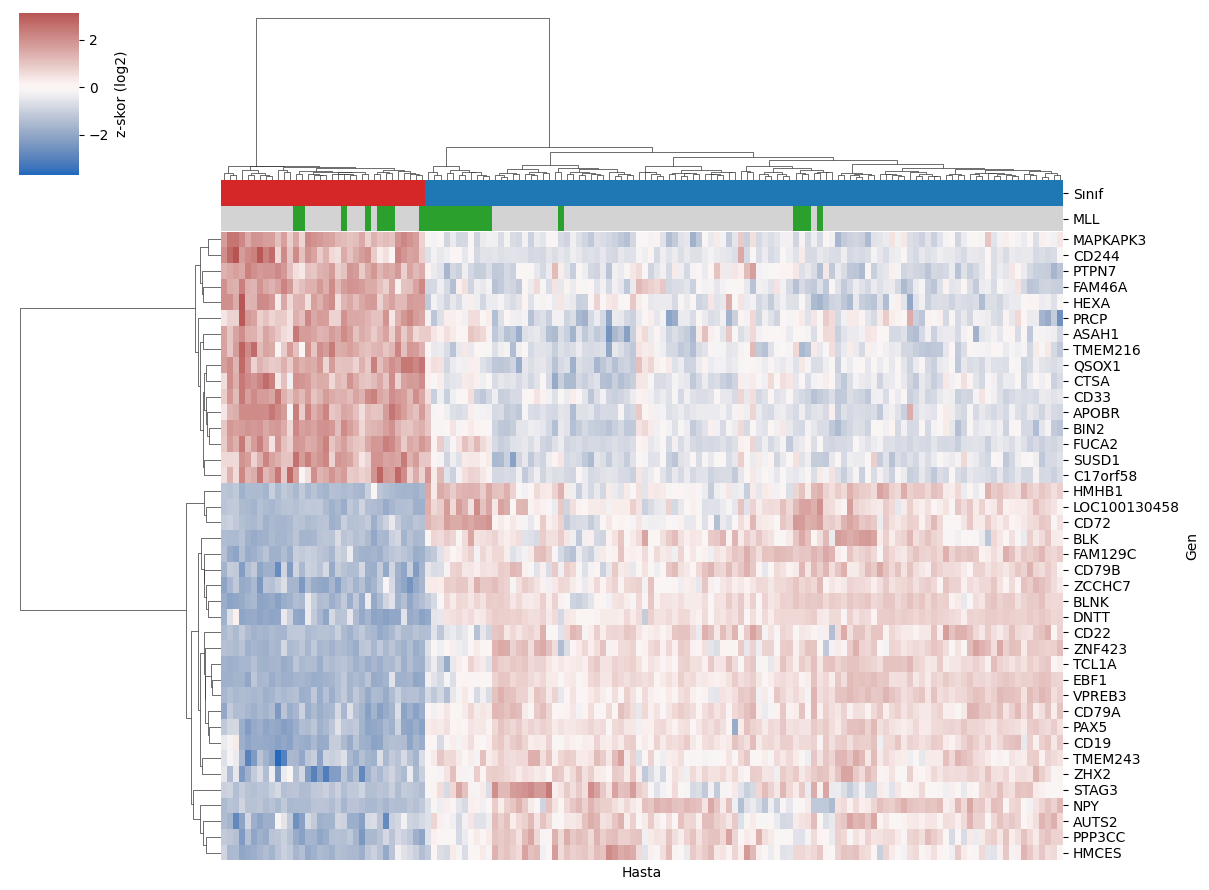

In [18]:
# [GSE14062-DE] ALL vs AML: Mann-Whitney + BH, ısı haritası ve hiyerarşik kümeleme
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests
import seaborn as sns

is_all2 = (y2 == "ALL").values
A, B = Xf.values[is_all2], Xf.values[~is_all2]
pv2 = np.array([mannwhitneyu(A[:, j], B[:, j], alternative="two-sided").pvalue for j in range(Xf.shape[1])])
qv2 = multipletests(pv2, method="fdr_bh")[1]
res2 = pd.DataFrame({"gene": Xf.columns, "p": pv2, "q": qv2,
                     "log2FC_ALL_minus_AML": A.mean(0) - B.mean(0)}).sort_values("p")
print("q < 0.05:", (res2.q < 0.05).sum(), "| q < 0.01:", (res2.q < 0.01).sum(), "/", len(res2))
print(res2.head(10))

top2 = res2.head(40)["gene"].tolist()
H = Xf[top2]; H_z = (H - H.mean()) / H.std()
cc = pd.DataFrame({
    "Sınıf": pd.Series(y2.values, index=H.index).map({"ALL": "tab:blue", "AML": "tab:red"}),
    "MLL": pd.Series(mll.values, index=H.index).map({True: "tab:green", False: "lightgray"})})
g = sns.clustermap(H_z.T, col_colors=cc, cmap="vlag", center=0, method="ward",
                   metric="euclidean", figsize=(12, 9), xticklabels=False, yticklabels=True,
                   cbar_kws={"label": "z-skor (log2)"})
g.ax_heatmap.set_xlabel("Hasta"); g.ax_heatmap.set_ylabel("Gen")
g.savefig("fig_gse14062_heatmap_top40.png", dpi=300)
plt.show()

Ortak gen (sembol): 753
Gen ortalama ifadesi Spearman rho: 0.46
log2FC (ALL-AML) Spearman rho: 0.32
Tüm genlerde log2FC işareti aynı olan oran: %58.8 (Golub'da FC=0 olan genler uyumsuz sayılır)
|log2FC| > 0.25: 128 gen, işaret uyumu %80.5
|log2FC| > 0.5: 49 gen, işaret uyumu %98.0
|log2FC| > 1.0: 19 gen, işaret uyumu %100.0


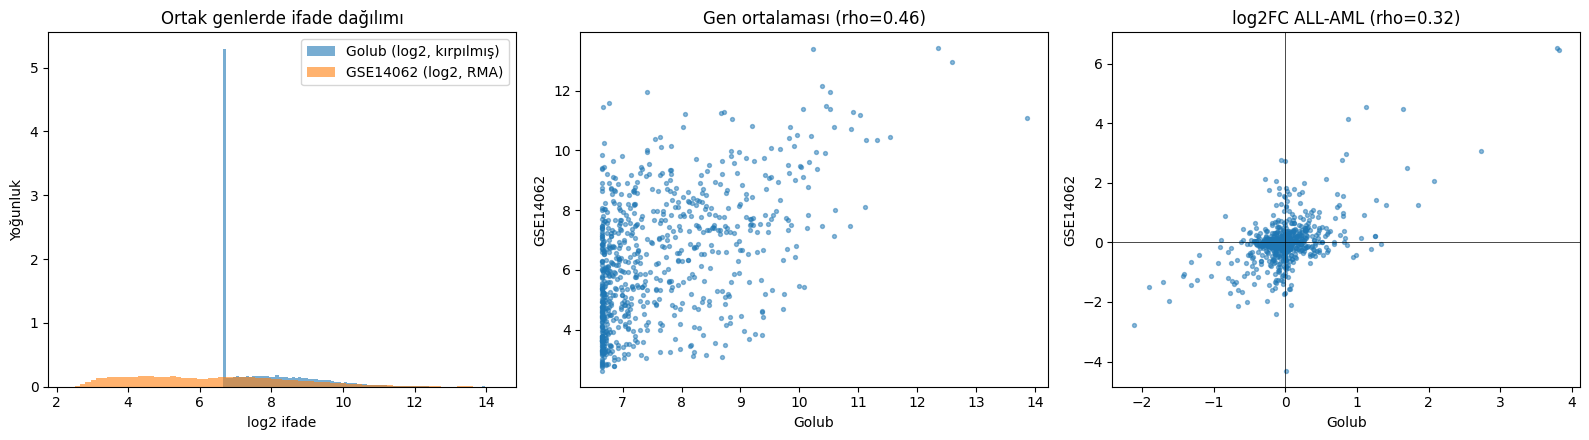

In [21]:
# [Cross-dataset] Ortak genlerde dağılım, gen ortalaması ve log2FC (ALL-AML) karşılaştırması
from scipy.stats import spearmanr

# 1) GenBank no -> gen sembolü eşlemesi (GPL570 üzerinden, çok genli problar hariç)
gpl3 = gpl[["GB_ACC", "Gene Symbol"]].dropna().copy()
gpl3["GB"] = gpl3["GB_ACC"].astype(str).str.replace(r"\.\d+$", "", regex=True)
gpl3 = gpl3[~gpl3["Gene Symbol"].str.contains("///")]
gb2sym = gpl3.drop_duplicates("GB").set_index("GB")["Gene Symbol"]

# 2) Golub: eşik (100-16000) + log2, aynı gene giden problar ortalanır
gb_g = pd.Series(all_X.columns, index=all_X.columns).str.extract(r"^([A-Z]+\d+)")[0]
sym_g = gb_g.map(gb2sym).dropna()
G = np.log2(all_X.clip(100, 16000))[sym_g.index]
G = G.T.groupby(sym_g.values).mean().T
y_g = lab.loc[G.index]

# 3) Ortak genler
common_sym = sorted(set(G.columns) & set(X_gene.columns))
G, Hh = G[common_sym], X_gene[common_sym]
print("Ortak gen (sembol):", len(common_sym))

# 4) Gen ortalaması ve log2FC (ALL - AML)
mean_g, mean_h = G.mean(), Hh.mean()
fc_g = G[y_g == "ALL"].mean() - G[y_g == "AML"].mean()
fc_h = Hh[(y2 == "ALL").values].mean() - Hh[(y2 == "AML").values].mean()

rho_mean = spearmanr(mean_g, mean_h)[0]
rho_fc = spearmanr(fc_g, fc_h)[0]
print(f"Gen ortalama ifadesi Spearman rho: {rho_mean:.2f}")
print(f"log2FC (ALL-AML) Spearman rho: {rho_fc:.2f}")
print(f"Tüm genlerde log2FC işareti aynı olan oran: %{(np.sign(fc_g) == np.sign(fc_h)).mean()*100:.1f} "
      "(Golub'da FC=0 olan genler uyumsuz sayılır)")

# 5) İşaret uyumu: yalnızca iki sette de belirgin farklı genlerde, birkaç eşikle
for thr in [0.25, 0.5, 1.0]:
    s = (fc_g.abs() > thr) & (fc_h.abs() > thr)
    agree = (np.sign(fc_g) == np.sign(fc_h))[s].mean() * 100
    print(f"|log2FC| > {thr}: {int(s.sum())} gen, işaret uyumu %{agree:.1f}")

# 6) Grafik
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
ax[0].hist(G.values.ravel(), bins=80, alpha=0.6, density=True, label="Golub (log2, kırpılmış)")
ax[0].hist(Hh.values.ravel(), bins=80, alpha=0.6, density=True, label="GSE14062 (log2, RMA)")
ax[0].set(title="Ortak genlerde ifade dağılımı", xlabel="log2 ifade", ylabel="Yoğunluk")
ax[0].legend()
ax[1].scatter(mean_g, mean_h, s=8, alpha=0.5)
ax[1].set(title=f"Gen ortalaması (rho={rho_mean:.2f})", xlabel="Golub", ylabel="GSE14062")
ax[2].scatter(fc_g, fc_h, s=8, alpha=0.5)
ax[2].axhline(0, c="k", lw=0.5); ax[2].axvline(0, c="k", lw=0.5)
ax[2].set(title=f"log2FC ALL-AML (rho={rho_fc:.2f})", xlabel="Golub", ylabel="GSE14062")
plt.tight_layout()
plt.savefig("fig_cross_dataset.png", dpi=300)
plt.show()